# SAP RPT 1.6 TechEd hands-on — Part 1: prediction and evaluation


This notebook covers the end-to-end SAP RPT 1.6 prediction workflow: serving setup, data preparation, leakage control, context construction, batched inference, baseline comparison, and evaluation.

If you are an experienced user or or you are specially interested in explainibility, you can run [Part 2](RPT_notebook_TechEd2026_part2_explainability.ipynb) for attention-derived column scores and relevant context-row explanations.

Note, that this notebooks contains all relevant helper functions needed to create the API request and to process the API response. 

## 0. Setup GenAIHub credentials and import packages

Import the required libraries

In [1]:
# Imports 
import os
from pathlib import Path
import io
import json
from typing import List, Dict, Tuple, Optional



import pandas as pd
import numpy as np
import requests
from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, accuracy_score, f1_score



# Performance-friendly display
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

/Users/d067487/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


### Import the SAP RPT 1.6 API credentials from your `.env` file


Run the cell below to load the environment variables.


In [ ]:
from dotenv import load_dotenv

load_dotenv()
AICORE_AUTH_URL = os.getenv("AICORE_AUTH_URL")
AICORE_CLIENT_ID = os.getenv("AICORE_CLIENT_ID")
AICORE_CLIENT_SECRET = os.getenv("AICORE_CLIENT_SECRET")
AICORE_RESOURCE_GROUP = os.getenv("AICORE_RESOURCE_GROUP")
AICORE_BASE_URL = os.getenv("AICORE_BASE_URL")
RPT_DEPLOYMENT_ID = os.getenv("RPT_DEPLOYMENT_ID")
RPT_LARGE_DEPLOYMENT_ID = os.getenv("RPT_LARGE_DEPLOYMENT_ID")


### Configure the remote deployment

This configuration is required for either credential option. Enter the deployment ID assigned for the exercise.


In [ ]:
BASE_DEPLOYMENT_URL = f"{AICORE_BASE_URL}/v2/inference/deployments/"
DEPLOYMENTS = {
    "sap-rpt-1.6": RPT_DEPLOYMENT_ID,
    "sap-rpt-1.6-large": RPT_LARGE_DEPLOYMENT_ID,
}


In [6]:
def select_model(model_name: str) -> Tuple[str, int]:
    if model_name not in DEPLOYMENTS:
        raise ValueError(f"Invalid model name: {model_name}")
    deployment_id = DEPLOYMENTS[model_name]
    if not deployment_id or deployment_id.startswith("YOUR_"):
        raise ValueError(f"Configure the deployment ID for {model_name}")
    deployment_url = BASE_DEPLOYMENT_URL + deployment_id
    max_context_rows = 8_192 if model_name == "sap-rpt-1.6-large" else 2_048
    return deployment_url, max_context_rows


In [7]:
RPT_DEPLOYMENT_URL, MAX_CONTEXT_ROWS = select_model('sap-rpt-1.6')

## Setup and test the authentication with AI Core using your credentials 

In [ ]:
def get_access_token() -> str:
    assert all([AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET]), (
        "Missing OAuth settings: AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET"
    )
    resp = requests.post(
        f"{AICORE_AUTH_URL}/oauth/token",
        data={"grant_type": "client_credentials", "client_id": AICORE_CLIENT_ID, "client_secret": AICORE_CLIENT_SECRET},
        timeout=60,
    )
    resp.raise_for_status()
    return resp.json()["access_token"]

print("Access token generated; last four characters:", get_access_token()[-4:])


Access token generated; last four characters: prEg


## Test the SAP RPT 1.6 API with dummy data

Generate a small table, send it as Parquet, and inspect predictions plus explanations.


In [9]:
#generate dummy data
context = pd.DataFrame({
    "row_id": [1, 2, 3, 4],
    "feature1": [10.0, 20.0, 30.0, 22.0],
    "feature2": [20.0, 15.0, 12.0, 17.2],
    "feature3": ["Lorem", "ipsum dolor", "sit", "amet"], 
    "my_target": ["A", "B", "A", "B"],
})

query = pd.DataFrame({
    "row_id": [5, 6],
    "feature1": [20.0, 11.0],
    "feature2": [16.0, 19.0],
    "feature3": ["random text", "dummy"],
    "my_target": [None, None],
})

table = pd.concat([context, query], ignore_index=True)

buffer = io.BytesIO()
table.to_parquet(buffer, index=False)
buffer.seek(0)

config = {
    "target_columns": [{
        "name": "my_target",
        "prediction_placeholder": None,
        "task_type": "classification",
        "top_k": 1,
    }],
}

#send the request
response = requests.post(
    RPT_DEPLOYMENT_URL+ '/predict_parquet',
    
    headers={
        "Authorization": f"Bearer {get_access_token()}",
        "ai-resource-group": AICORE_RESOURCE_GROUP,
    },
    files={
        "file": (
            "request.parquet",
            buffer,
            "application/vnd.apache.parquet",
        ),
    },
    data={
        "prediction_config": json.dumps(config),
        "index_column": "row_id",
        "parse_data_types": "false",
    },
    timeout=300,
)

response.raise_for_status()
predictions = response.json()
print(json.dumps(predictions, indent=2))



{
  "explanations": null,
  "id": "6e7ada44-0fa5-4796-808a-3a0978d2e2c4",
  "metadata": {
    "context_mode": "default",
    "num_columns": 5,
    "num_predictions": 2,
    "num_query_rows": 2,
    "num_rows": 6
  },
  "predictions": [
    {
      "my_target": [
        {
          "confidence": 0.94,
          "confidence_interval": null,
          "prediction": "B"
        }
      ],
      "row_id": 5
    },
    {
      "my_target": [
        {
          "confidence": 0.77,
          "confidence_interval": null,
          "prediction": "A"
        }
      ],
      "row_id": 6
    }
  ],
  "status": {
    "code": 0,
    "message": "ok"
  }
}


## 1. Select data to predict on
Load the data from local CSV file into a Pandas DataFrame that will serve as the basis for all subsequent steps. `used_cars_24.csv` is provided as en example for illustrative purposes - idea would be to experiment with an own local csv file.

In [10]:
candidates = [
    Path("used_cars_24.csv"),  # Kernel started in the Notebooks directory
    Path("Notebooks/used_cars_24.csv"),  # Kernel started at the sap-rpt-enablement root
    Path("sap-rpt-enablement/Notebooks/used_cars_24.csv"),  # Kernel started at the workspace root
]
CSV_PATH = next((path for path in candidates if path.exists()), None)
assert CSV_PATH is not None, f"Dataset not found; checked {candidates}"
df = pd.read_csv(CSV_PATH)
assert len(df) > 0
print(f"Loaded rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
df.head()


Loaded rows: 5918
Columns: ['idx', 'Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership', 'EMI (monthly)']


,idx,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,EMI (monthly)
0,0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2,7350
1,1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1,7790
2,2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2,5098
3,3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1,6816
4,4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1,4642


## 2. Define prediction target
Define the prediction target column that represent the business outcome you want to predict. For this used cars dataset, we'll predict the car price.

In [11]:
# Choose your target column 
TARGET_COLUMN = "Price" #"Fuel"

# Validate target column exists
assert TARGET_COLUMN in df.columns, f"Target column {TARGET_COLUMN} not found in dataset!"

print(f"Target column: {TARGET_COLUMN}")
print(f"Target distribution:\n{df[TARGET_COLUMN].value_counts().sort_index()}")
df[[TARGET_COLUMN]].head()

Target column: Price
Target distribution:
Price
91000      1
103599     1
105000     1
107000     1
107399     1
          ..
2724199    1
2976299    1
3495000    1
4100000    1
6500000    1
Name: count, Length: 4139, dtype: int64


,Price
0,330399
1,350199
2,229199
3,306399
4,208699


## 3. Define task type
Choose regression for numeric targets such as price or classification for categorical targets such as fuel type. Setting the task explicitly makes the SAP RPT 1.6 exercise reproducible.


Task type: regression


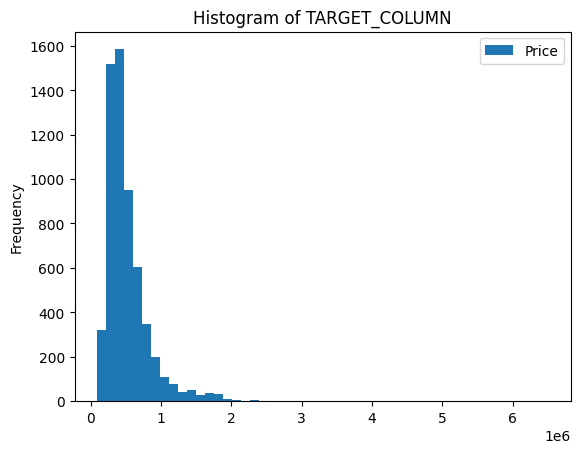

In [12]:
# Set task type explicitly: "regression" or "classification"
# For e.g. Price prediction, we use regression
TASK_TYPE = "regression" # "classification"

if TASK_TYPE == "regression":
    # Coerce target numeric where possible
    df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
    df[[TARGET_COLUMN]].plot.hist(bins=50, title="Histogram of TARGET_COLUMN")
elif TASK_TYPE == "classification":
    # Treat as strings for classification
    df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(str)
    df[TARGET_COLUMN].value_counts().sort_index().plot.bar(color='skyblue', alpha=0.75, title='Value Counts of TARGET_COLUMN')
else:
    raise ValueError(f"Unknown TASK_TYPE: {TASK_TYPE}")

print(f"Task type: {TASK_TYPE}")

## 4. Conduct leakage control
Remove any known leakers if present. 

(A column (feature) is allowed only if it is reliably known at the time of prediction. Any information that becomes available after the prediction moment is a leakage candidate and should be removed. Also other columns that contain information which would give trivial conclusion about the target and that are not available in real time scenarios, could be a leaker and results in unrealistically high performance scores.)

In [13]:
# Remove target leakage and row identifiers that should not become model features.
LEAKER_COLUMNS: List[str] = ["EMI (monthly)"]
IDENTIFIER_COLUMNS: List[str] = ["idx"]
excluded_columns = [
    column for column in LEAKER_COLUMNS + IDENTIFIER_COLUMNS if column in df.columns
]
df_clean = df.drop(columns=excluded_columns).copy()
print(f"Excluded non-feature columns: {excluded_columns}")
print(f"Remaining columns: {df_clean.columns.tolist()}")
df_clean.head()


Excluded non-feature columns: ['EMI (monthly)', 'idx']
Remaining columns: ['Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership
0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2
1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1
2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2
3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1
4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1


## 5. Define baselines
Before evaluating SAP RPT 1.6, define what good performance means. Compare against at least a naïve historical median or majority-class baseline and, where possible, an expert rule.


In [14]:
def baseline_predictions(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    task_type: str,
) -> Dict[str, pd.Series]:
    results: Dict[str, pd.Series] = {}

    if task_type == "regression":
        # Naive: global median
        median_val = float(np.nanmedian(y_train.values))
        results["Naive-Median"] = pd.Series([median_val] * len(X_test), index=X_test.index, name=TARGET_COLUMN)
    elif task_type == "classification":
        # Naive: majority class
        majority = y_train.value_counts().idxmax()
        results["Naive-Majority"] = pd.Series([majority] * len(X_test), index=X_test.index, name=TARGET_COLUMN)
    else:
        raise ValueError(f"Unknown task type: {task_type}")

    return results

## 6. Define evaluation metrics
We recommend to pick evaluation metrics which reflect the business cost of errors. For regression, e.g., MAE/MAPE. For classification, e.g., accuracy.

In [15]:
def compute_metrics(y_true: pd.Series, y_pred: pd.Series, task_type: str) -> Dict[str, float]:
    if task_type == "regression":
        return {
            "MAE": float(mean_absolute_error(y_true=y_true, y_pred=y_pred)),
            "MAPE": float(mean_absolute_percentage_error(y_true=y_true, y_pred=y_pred)),
        }
    elif task_type == "classification":
        return {
            "Accuracy": float(accuracy_score(y_true=y_true, y_pred=y_pred)),
            "F1-Macro": float(f1_score(y_true=y_true, y_pred=y_pred, average="macro")),
        }
    else:
        raise ValueError(f"Unknown task type: {task_type}")

## 7. Define split strategy
Define how data is separated into context rows (used for in-context learning, also called training set for classical models) and evaluation rows (used for measuring performance, also called test set). 

If we have a dataset where time place an import role, we can split the data based on a feature (`SORTING_COLUMN` below) containing information about this time dimension. 

If this is not the case, we use a stratified split for classification and a random split for regression below. 


In [16]:
# Simple, readable split strategy
TEST_SIZE = 0.2
SORTING_COLUMN: Optional[str] = None

# Rows without ground truth cannot be evaluated. Feature nulls remain null for the service.
df_model = df_clean.dropna(subset=[TARGET_COLUMN]).copy()
if SORTING_COLUMN:
    assert SORTING_COLUMN in df_model.columns
    df_sorted = df_model.sort_values(by=SORTING_COLUMN)
    n_test = max(1, int(len(df_sorted) * TEST_SIZE))
    df_train, df_test = df_sorted.iloc[:-n_test], df_sorted.iloc[-n_test:]
else:
    stratify = df_model[TARGET_COLUMN] if TASK_TYPE == "classification" else None
    df_train, df_test = train_test_split(df_model, test_size=TEST_SIZE, random_state=42, stratify=stratify)
assert len(df_train) > 0 and len(df_test) > 0
FEATURE_COLUMNS = [column for column in df_model.columns if column != TARGET_COLUMN]
X_train = df_train[FEATURE_COLUMNS].copy()
y_train = df_train[TARGET_COLUMN].copy()
X_test = df_test[FEATURE_COLUMNS].copy()
y_test = df_test[TARGET_COLUMN].copy()
print(f"Train: {len(X_train)} rows, Test: {len(X_test)} rows, Features: {len(FEATURE_COLUMNS)}")
print(f"Feature columns: {FEATURE_COLUMNS}")


Train: 4734 rows, Test: 1184 rows, Features: 8
Feature columns: ['Car Brand', 'Model', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


## 8. Define context

This SAP RPT 1.6 workshop configuration uses up to 2,048 context rows for sap-rpt-1.6 and 8,192 for the configured sap-rpt-1.6-large endpoint. Context selection can affect predictions and explanations.


In [ ]:
#for exercise 3 (Tabular AI orchestration) you need split the data into 2 csv files: query and context 
context_rows = pd.concat([X_train, y_train], axis=1)
query_rows = pd.concat([X_test, y_test], axis=1)
context_rows.to_csv('used_cars_24_context.csv', index=False)
query_rows.to_csv('used_cars_24_query.csv', index=False)



# MAX_CONTEXT_ROWS was set when selecting the SAP RPT 1.6 endpoint.
X_context = X_train.sample(n=min(MAX_CONTEXT_ROWS, len(X_train)), random_state=42)
y_context = y_train.loc[X_context.index]
print(f"Context rows: {len(X_context)}")


Context rows: 2048


## 9. Construct the SAP RPT 1.6 JSON request
Build one request table containing context rows with known targets and query rows with a prediction placeholder. A synthetic index column supports response alignment and is not used as a feature.


In [18]:
RPT_PREDICTION_PLACEHOLDER = "[PREDICT]"
MAX_QUERY_ROWS = 128


def to_python_type(val):
    """Convert numpy/pandas types to native Python types for JSON serialization."""
    if isinstance(val, (np.integer, np.floating)):
        return val.item()
    if isinstance(val, np.ndarray):
        return val.tolist()
    if isinstance(val, pd.Timestamp):
        return val.strftime('%Y-%m-%d')
    if pd.isna(val):
        return None
    return val


def build_rows(X_context: pd.DataFrame, y_context: pd.Series, X_query: pd.DataFrame) -> List[Dict]:
    rows: List[Dict] = []
    # Context rows with actual target
    for i, (_, row) in enumerate(X_context.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = to_python_type(y_context.iloc[i])
        rd["__row_idx__"] = f"1{i:06d}"
        rows.append(rd)
    # Query rows with placeholder
    for i, (_, row) in enumerate(X_query.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = RPT_PREDICTION_PLACEHOLDER
        rd["__row_idx__"] = f"2{i:06d}"
        rows.append(rd)
    return rows

## 10. Run inference and retrieve predictions
Call the deployed SAP-RPT endpoint, passing the data as a JSON payload. 

In [ ]:
def call_rpt_predict(payload: Dict, access_token: str) -> Dict:
    assert RPT_DEPLOYMENT_URL, "RPT_DEPLOYMENT_URL must be set to call the API"
    url = f"{RPT_DEPLOYMENT_URL}/predict"
    headers = {
        "Content-Type": "application/json",
        "Authorization": f"Bearer {access_token}",
        "ai-resource-group": AICORE_RESOURCE_GROUP,
    }
    response = requests.post(url, headers=headers, json=payload, timeout=300)
    try:
        result = response.json()
    except ValueError as exc:
        raise RuntimeError(f"Non-JSON response (HTTP {response.status_code}): {response.text[:1000]}") from exc
    if not response.ok:
        raise RuntimeError(f"HTTP {response.status_code}: {json.dumps(result, indent=2)}")
    status = result.get("status", {})
    if status.get("code", 3) >= 2:
        raise RuntimeError(f"Prediction failed: {json.dumps(result, indent=2)}")
    if status.get("code") == 1:
        print(f"Serving warning: {status.get('message')}")
    return result


def extract_predictions(response: Dict, target_column: str) -> Tuple[List, List[float]]:
    preds = [row[target_column][0]["prediction"] for row in response.get("predictions", [])]
    confs = [row[target_column][0].get("confidence", 0.0) for row in response.get("predictions", [])]
    pred_intervals = [row[target_column][0].get("confidence_interval", 0.0) for row in response.get("predictions", [])]
    return preds, confs, pred_intervals


def run_rpt_in_batches(X_context: pd.DataFrame, y_context: pd.Series, X_eval: pd.DataFrame, task_type: str) -> Tuple[pd.Series, pd.Series, pd.Series]:
    access_token = get_access_token()

    # Always use batching (single batch if small enough)
    num_batches = (len(X_eval) + MAX_QUERY_ROWS - 1) // MAX_QUERY_ROWS
    print(f"Batching {len(X_eval)} test rows into {num_batches} batch(es) of max {MAX_QUERY_ROWS}...")
    preds_all: List = []
    confs_all: List[float] = []
    pred_intervals_all: List = []

    for start in tqdm(
        range(0, len(X_eval), MAX_QUERY_ROWS),
        total=num_batches,
        desc=f"Processing prediction batches over API [B={MAX_QUERY_ROWS}]",
    ):
        X_batch = X_eval.iloc[start : start + MAX_QUERY_ROWS]
        rows = build_rows(X_context=X_context, y_context=y_context, X_query=X_batch)
        payload = {
            "prediction_config": {
                "target_columns": [
                    {
                        "name": TARGET_COLUMN,
                        "prediction_placeholder": RPT_PREDICTION_PLACEHOLDER,
                        "task_type": task_type,
                    }
                ]
            },
            "index_column": "__row_idx__",
            "rows": rows,
        }

        response = call_rpt_predict(payload=payload, access_token=access_token)
        preds, confs, pred_intervals = extract_predictions(response=response, target_column=TARGET_COLUMN)
        preds_all.extend(preds)
        confs_all.extend(confs)
        pred_intervals_all.extend(pred_intervals)

    y_pred = pd.Series(preds_all, index=X_eval.index, name=TARGET_COLUMN)
    # Ensure numeric conversions for regression
    if task_type == "regression":
        y_pred = pd.to_numeric(y_pred, errors="coerce")
    conf_series = pd.Series(confs_all, index=X_eval.index, name="confidence")
    pred_intervals_series = pd.Series(pred_intervals_all, index=X_eval.index, name="pred_intervals")
    return y_pred, conf_series, pred_intervals_series

In [20]:
# Compute baselines (naive only)
baseline_preds = baseline_predictions(X_train=X_train, y_train=y_train, X_test=X_test, task_type=TASK_TYPE)

# Assert RPT creds and URL are set before calling API
assert AICORE_AUTH_URL and AICORE_CLIENT_ID and AICORE_CLIENT_SECRET and AICORE_RESOURCE_GROUP, (
    "All RPT credentials must be set in environment: AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET, AICORE_RESOURCE_GROUP"
)
assert RPT_DEPLOYMENT_URL, "RPT_DEPLOYMENT_URL constant must be set to a valid endpoint"

# Call RPT (requires valid deployment + credentials)
y_pred_rpt, rpt_conf, rpt_pred_intervals_series = run_rpt_in_batches(
    X_context=X_context,
    y_context=y_context,
    X_eval=X_test,
    task_type=TASK_TYPE,
)
rpt_pred_intervals = pd.DataFrame(rpt_pred_intervals_series.tolist(), columns=['lower_bound', 'upper_bound'], index=rpt_pred_intervals_series.index)

# Collect metrics
all_metrics: Dict[str, Dict[str, float]] = {}
for name, y_pred_baseline in baseline_preds.items():
    all_metrics[name] = compute_metrics(y_true=y_test, y_pred=y_pred_baseline, task_type=TASK_TYPE)

all_metrics["SAP RPT 1.6"] = compute_metrics(y_true=y_test, y_pred=y_pred_rpt, task_type=TASK_TYPE)

print("Metrics by approach:")
for k, v in all_metrics.items():
    print(k, v)

Batching 1184 test rows into 10 batch(es) of max 128...


Processing prediction batches over API [B=128]: 100%|██████████| 10/10 [00:08<00:00,  1.25it/s]

Metrics by approach:
Naive-Median {'MAE': 190290.25, 'MAPE': 0.3775847459240602}
SAP RPT 1.6 {'MAE': 44622.89978357263, 'MAPE': 0.09289424046721603}


## 11. Compute metrics and analyse results
Evaluate predictions against your baseline predictions by using the defined metrics.

In [21]:
# Display combined ground truth, predictions, and confidence
results_df = X_test.copy()
results_df[f"Ground Truth {TARGET_COLUMN}"] = y_test
results_df[f"Prediction SAP RPT 1.6 {TARGET_COLUMN}"] = y_pred_rpt
results_df["Confidence SAP RPT 1.6"] = rpt_conf
results_df["Confidence-Interval [lower bound]"] = rpt_pred_intervals["lower_bound"]
results_df["Confidence-Interval [upper bound]"] = rpt_pred_intervals["upper_bound"]


results_df

,Car Brand,Model,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,Ground Truth Price,Prediction SAP RPT 1.6 Price,Confidence SAP RPT 1.6,Confidence-Interval [lower bound],Confidence-Interval [upper bound]
1535,Maruti,SwiftVDI,2014,Delhi,Diesel,117196,Manual,1,328599,385175.37500,None,320974.0000,4.867990e+05
2302,Volkswagen,PoloGT TSI,2018,Delhi,Petrol,43872,Manual,1,716799,801929.75000,None,596192.1875,1.133529e+06
1197,Maruti,Swift DzireVDI BS IV,2013,Delhi,Diesel,79248,Manual,2,358699,386118.87500,None,268210.0000,6.893830e+05
5057,Maruti,ErtigaZDI,2014,Bangalore,Diesel,94656,Manual,3,676199,630739.62500,None,509999.6250,7.996990e+05
5793,Volkswagen,VentoHIGHLINE TDI AT,2015,Chennai,Diesel,90897,Automatic,2,644199,566454.56250,None,425208.0000,8.505802e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1330,Maruti,SwiftVXI,2011,Delhi,Petrol,95427,Manual,2,262399,280788.65625,None,212434.0000,3.487130e+05
1873,Toyota,Innova2.5 VX 7 STR BS IV,2013,Delhi,Diesel,140808,Manual,1,708599,679049.87500,None,523619.0312,9.141011e+05
2029,Maruti,Swift DzireVDI BS IV,2012,Delhi,Diesel,110400,Manual,2,282599,338916.93750,None,268210.0000,4.330840e+05
2209,Maruti,Swift DzireLXI 1.2 BS IV,2015,Delhi,Petrol,69364,Manual,1,367499,428948.25000,None,363199.0000,5.236190e+05


## Plot metrics comparison
Simple bar plot comparing metrics from all baselines and RPT.

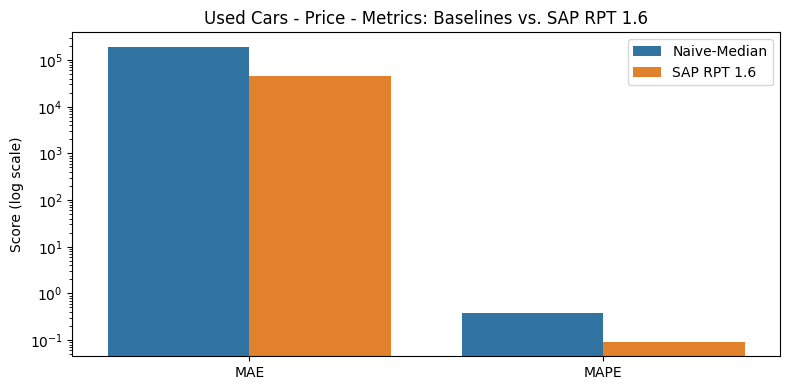

In [22]:
# Prepare long-form for plotting
records = []
for approach, mdict in all_metrics.items():
    for metric, value in mdict.items():
        records.append({"approach": approach, "metric": metric, "value": value})
plot_df = pd.DataFrame(records)

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x="metric", y="value", hue="approach")
plt.title(f"Used Cars - {TARGET_COLUMN} - Metrics: Baselines vs. SAP RPT 1.6")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="best")

# Use logarithmic scale for regression metrics (large value differences)
if TASK_TYPE == "regression":
    plt.yscale("log")
    plt.ylabel("Score (log scale)")

plt.tight_layout()
plt.show()

In [23]:
## Plot some example predictions 

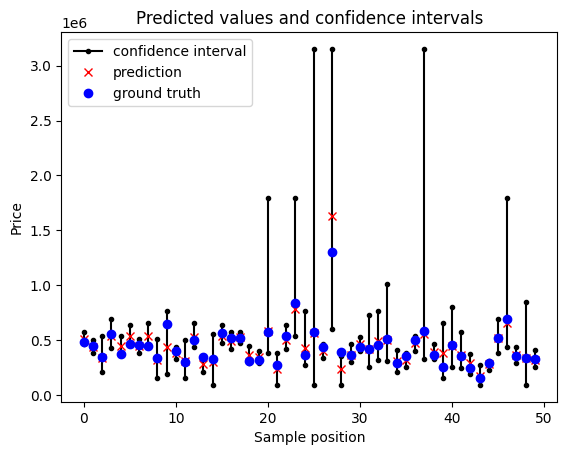

In [24]:
n_test_plot = min(50, len(y_pred_rpt))
index_plot = y_pred_rpt.sample(n=n_test_plot, random_state=0).index
for position, row_index in enumerate(index_plot):
    interval = rpt_pred_intervals.loc[row_index]
    if interval.notna().all():
        plt.plot([position, position], [interval["lower_bound"], interval["upper_bound"]], ".-k")
    plt.plot(position, y_pred_rpt.loc[row_index], "xr")
    plt.plot(position, y_test.loc[row_index], "ob")
plt.legend(["confidence interval", "prediction", "ground truth"])
plt.title("Predicted values and confidence intervals")
plt.xlabel("Sample position")
plt.ylabel(TARGET_COLUMN)
plt.show()


## 12. Follow-up tasks: Evaluate & Iterate
Iterate on target definition, leakage control, split strategy, context selection, and feature set. Further challenges

- Search for outliers (e.g. a car sale where the price was higher than the upper bound of the model predition)
- Explore model explanation explanations features (see also the dummy call above) and identify which features are most important on average
- Enter the details of your own car and get a price estimate of the model

## Part 1 complete

You have prepared context/query rows, called SAP RPT 1.6, compared it with a naïve baseline, and inspected prediction confidence information. Continue with the explainability notebook to construct an explanation request and interpret its outputs.
